### K Nearest Neighbours

### Build a model that predicts Drug to the patient on basis of their medical records

### Data Gathering/Data Ingestion

In [1]:
from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
path = r"https://raw.githubusercontent.com/kavaderohan2005-netizen/Datasets/refs/heads/main/drug200.csv"
import pandas as pd
df = pd.read_csv(path)
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


### Y: Drug

In [3]:
df['Drug'].value_counts()

Drug
DrugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64

In [4]:
len(df)

200

In [5]:
((df['Drug'].value_counts())/len(df))*100

Drug
DrugY    45.5
drugX    27.0
drugA    11.5
drugC     8.0
drugB     8.0
Name: count, dtype: float64

<Axes: xlabel='Drug'>

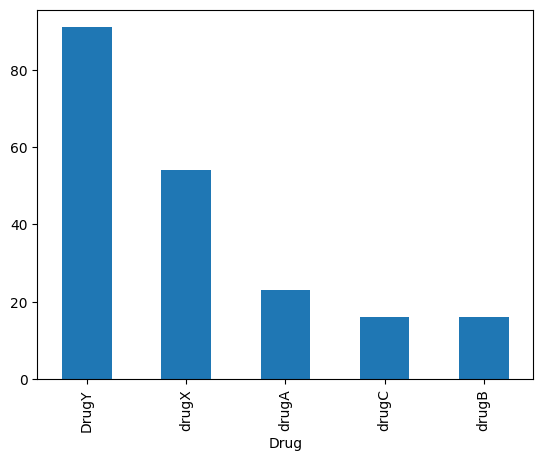

In [6]:
df['Drug'].value_counts().plot(kind='bar')

### The data appears to be imbalanced. We have to apply resampling technique

In [7]:

len(df)

200

### Separate X and Y features

    Y :Drug

In [8]:
X = df.drop(columns=['Drug'])
Y = df[['Drug']]
X.head()

,Age,Sex,BP,Cholesterol,Na_to_K
0,23,F,HIGH,HIGH,25.355
1,47,M,LOW,HIGH,13.093
2,47,M,LOW,HIGH,10.114
3,28,F,NORMAL,HIGH,7.798
4,61,F,LOW,HIGH,18.043


In [10]:
Y.head()

,Drug
0,DrugY
1,drugC
2,drugC
3,drugX
4,DrugY


### Split the data into training and testing
    
    training: 80% 
    testing: 20%

In [11]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(X,Y,train_size=0.8,random_state=21)

### Data Preprocessing and Data Cleaning

In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

cat = list(X.select_dtypes(include='object').columns) 
con = list(X.select_dtypes(include='number').columns)

num_pipe = make_pipeline(
    SimpleImputer(strategy='median'),
    MinMaxScaler()
)

cat_pipe = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore',sparse_output=False)
)

pre = ColumnTransformer([(
    "cat",cat_pipe,cat
),
("con",num_pipe,con)]).set_output(transform='pandas')
pre

,transformers,"[('cat', ...), ('con', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None


In [14]:
pre.fit(xtrain)

,transformers,"[('cat', ...), ('con', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None


In [15]:
xtrain_pre = pre.transform(xtrain)
xtest_pre = pre.transform(xtest)

In [16]:

from imblearn.over_sampling import SMOTE

In [17]:
smote = SMOTE()
x_sampl,y_sampl = smote.fit_resample(xtrain_pre,ytrain)

In [18]:
y_sampl['Drug'].value_counts()

Drug
drugA    70
drugX    70
drugB    70
drugC    70
DrugY    70
Name: count, dtype: int64

### Model Building: KNearest Neighbours

In [19]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier() # by default, 5 neighbours will be considered
model.fit(x_sampl,y_sampl['Drug'])

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [20]:
model.score(x_sampl,y_sampl)

0.9257142857142857

In [21]:
model.score(xtest_pre,ytest)

0.625

### This model is resulting overfitting scenario.

### Hyperparameter tuning

In [22]:
import numpy as np
error_rates = []

for i in range(2,10):
    model = KNeighborsClassifier(n_neighbors=i)
    model.fit(x_sampl,y_sampl)
    ypreds = model.predict(xtest_pre)
    errors = np.mean(ypreds!=ytest['Drug'])
    error_rates.append(errors)

error_rates

[np.float64(0.175),
 np.float64(0.275),
 np.float64(0.25),
 np.float64(0.375),
 np.float64(0.35),
 np.float64(0.425),
 np.float64(0.425),
 np.float64(0.5)]

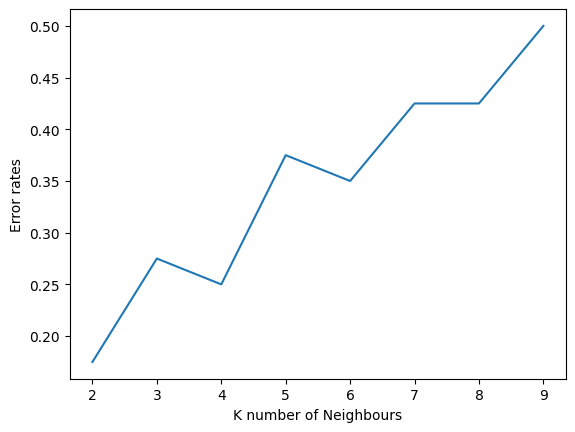

In [23]:
import matplotlib.pyplot as plt
plt.plot(range(2,10),error_rates)
plt.xlabel("K number of Neighbours")
plt.ylabel("Error rates")
plt.show()

In [24]:
model_3 = KNeighborsClassifier(n_neighbors=4)
model_3.fit(x_sampl,y_sampl)

,n_neighbors,4
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [25]:
model_3.score(x_sampl,y_sampl)

0.96

In [26]:
model_3.score(xtest_pre,ytest)

0.75

### This model is resulting in overfitting where it is performing very well on training data but failing on unseen data

**This model cannot be finalised**